In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
tf.random.set_seed(42)

In [25]:
df = pd.read_csv("diabetes.csv")


In [26]:
df = pd.read_csv("diabetes.csv")

In [59]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 768
Number of columns: 9


In [60]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

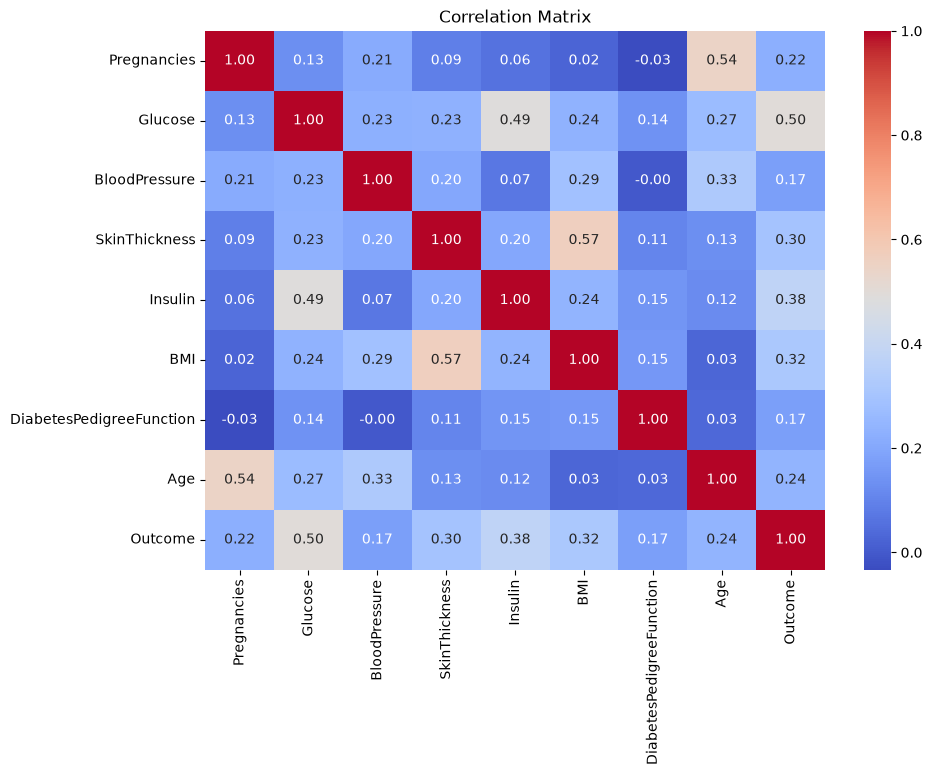

In [61]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

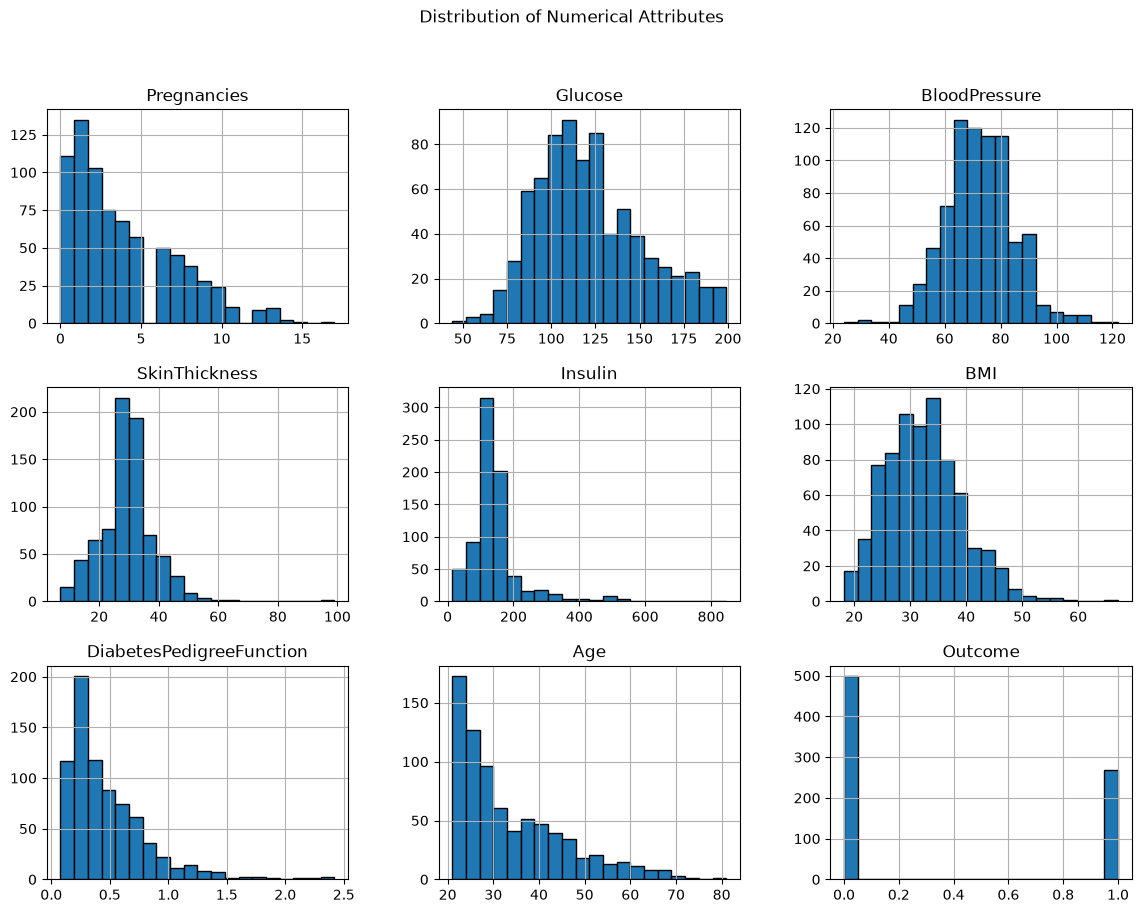

In [62]:
df.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Attributes")
plt.show()

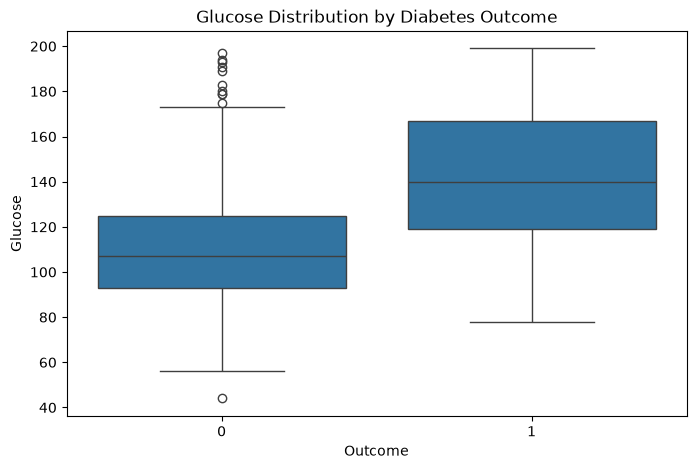

In [63]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Outcome",
    y="Glucose",
    data=df
)

plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")
plt.show()

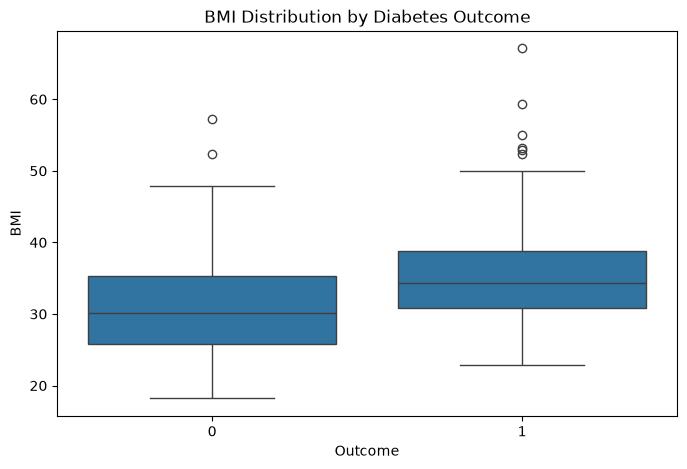

In [64]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Outcome",
    y="BMI",
    data=df
)

plt.title("BMI Distribution by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")
plt.show()

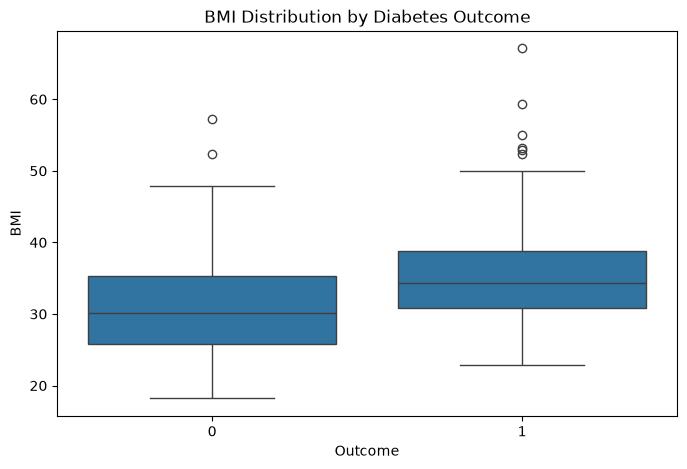

In [65]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Outcome",
    y="BMI",
    data=df
)

plt.title("BMI Distribution by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")
plt.show()

In [66]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [67]:
print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [68]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [69]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [70]:
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (537, 8)
Validation data: (115, 8)
Testing data: (116, 8)


In [71]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [72]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

In [73]:
def build_ann(
    activation="relu",
    optimizer="adam",
    learning_rate=0.001
):
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)),

        Dense(16, activation=activation),
        Dropout(0.2),

        Dense(8, activation=activation),

        Dense(1, activation="sigmoid")
    ])

    if optimizer == "sgd":
        selected_optimizer = SGD(
            learning_rate=learning_rate
        )

    elif optimizer == "momentum":
        selected_optimizer = SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    elif optimizer == "rmsprop":
        selected_optimizer = RMSprop(
            learning_rate=learning_rate
        )

    elif optimizer == "adam":
        selected_optimizer = Adam(
            learning_rate=learning_rate
        )

    else:
        raise ValueError("Invalid optimizer selected")

    model.compile(
        optimizer=selected_optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [74]:
model = build_ann(
    activation="relu",
    optimizer="adam",
    learning_rate=0.001
)

In [75]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [76]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

In [77]:
start_time = time.time()

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

training_time = time.time() - start_time

print("Training time:", training_time, "seconds")

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4227 - loss: 0.7897 - val_accuracy: 0.5391 - val_loss: 0.7025
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5363 - loss: 0.7299 - val_accuracy: 0.6348 - val_loss: 0.6614
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6108 - loss: 0.6803 - val_accuracy: 0.6522 - val_loss: 0.6336
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6331 - loss: 0.6395 - val_accuracy: 0.6783 - val_loss: 0.6124
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6704 - loss: 0.6111 - val_accuracy: 0.6696 - val_loss: 0.5950
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6909 - loss: 0.5862 - val_accuracy: 0.6696 - val_loss: 0.5813
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7095 - loss: 0.5679 - val_accuracy: 0.6957 - val_loss: 0.5701
Epoch 8/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7207 - loss: 0.5415 - val_accuracy: 0.7043 

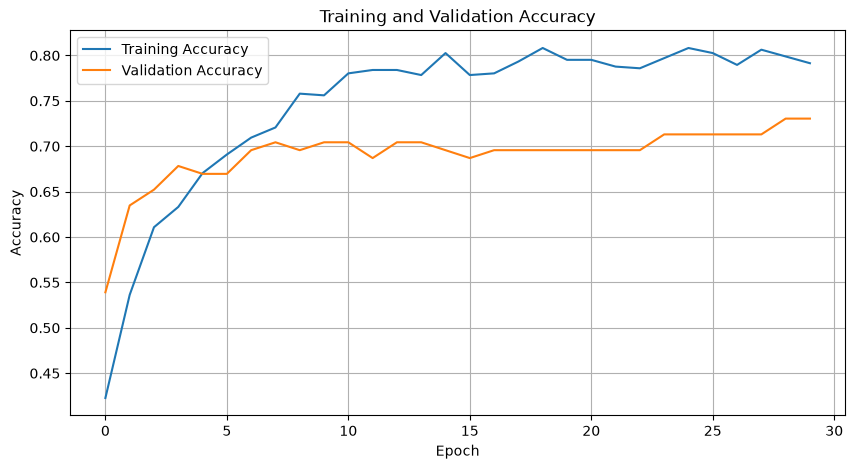

In [78]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

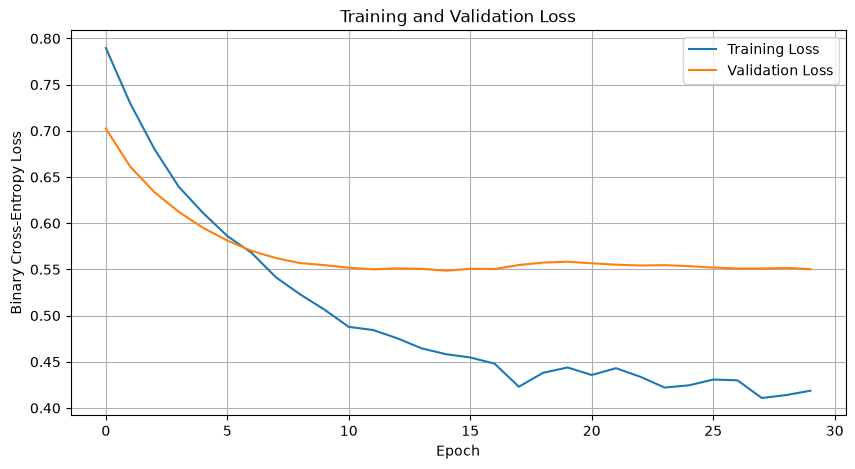

In [79]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid()
plt.show()

In [80]:
y_probability = model.predict(X_test_scaled).ravel()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


In [81]:
y_pred = (y_probability >= 0.5).astype(int)

In [82]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)
print("ROC-AUC  :", roc_auc)

Accuracy : 0.8103448275862069
Precision: 0.7714285714285715
Recall   : 0.6585365853658537
F1-score : 0.7105263157894737
ROC-AUC  : 0.8917073170731707


In [83]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86        75
           1       0.77      0.66      0.71        41

    accuracy                           0.81       116
   macro avg       0.80      0.78      0.78       116
weighted avg       0.81      0.81      0.81       116



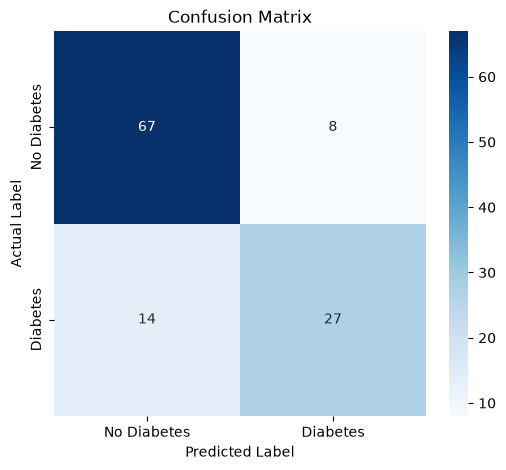

In [85]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()




In [ ]:
# comparing different activation functions

In [86]:
from tensorflow.keras.layers import LeakyReLU

In [87]:
def build_activation_model(activation_name):
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)),

        Dense(16),

        LeakyReLU(alpha=0.01)
        if activation_name == "leaky_relu"
        else Dense(16, activation=activation_name),

        Dropout(0.2),

        Dense(8),

        LeakyReLU(alpha=0.01)
        if activation_name == "leaky_relu"
        else Dense(8, activation=activation_name),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [99]:
def build_activation_model(activation_name):
    model = Sequential()

    model.add(Input(shape=(X_train_scaled.shape[1],)))

    if activation_name == "leaky_relu":
        model.add(Dense(16))
        model.add(LeakyReLU(negative_slope=0.01))
    else:
        model.add(Dense(16, activation=activation_name))

    model.add(Dropout(0.2))

    if activation_name == "leaky_relu":
        model.add(Dense(8))
        model.add(LeakyReLU(negative_slope=0.01))
    else:
        model.add(Dense(8, activation=activation_name))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [100]:
def build_activation_model(activation_name):
    model = Sequential()

    model.add(Input(shape=(X_train_scaled.shape[1],)))

    if activation_name == "leaky_relu":
        model.add(Dense(16))
        model.add(LeakyReLU(negative_slope=0.01))
    else:
        model.add(Dense(16, activation=activation_name))

    model.add(Dropout(0.2))

    if activation_name == "leaky_relu":
        model.add(Dense(8))
        model.add(LeakyReLU(negative_slope=0.01))
    else:
        model.add(Dense(8, activation=activation_name))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [89]:
activation_names = [
    "sigmoid",
    "relu",
    "tanh",
    "leaky_relu"
]

activation_results = []
activation_histories = {}

for activation_name in activation_names:
    print("\nTraining with activation:", activation_name)

    tf.random.set_seed(42)

    activation_model = build_activation_model(activation_name)

    start_time = time.time()

    activation_history = activation_model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=150,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    elapsed_time = time.time() - start_time

    probability = activation_model.predict(
        X_test_scaled,
        verbose=0
    ).ravel()

    prediction = (probability >= 0.5).astype(int)

    activation_results.append({
        "Activation": activation_name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1 Score": f1_score(y_test, prediction),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "Training Time": elapsed_time,
        "Epochs": len(activation_history.history["loss"])
    })

    activation_histories[activation_name] = activation_history


Training with activation: sigmoid

Training with activation: relu

Training with activation: tanh

Training with activation: leaky_relu


In [90]:
activation_results_df = pd.DataFrame(activation_results)




activation_results_df

,Activation,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time,Epochs
0,sigmoid,0.818966,0.777778,0.682927,0.727273,0.903740,9.928262,53
1,relu,0.905172,0.894737,0.829268,0.860759,0.952520,20.249653,132
2,tanh,0.836207,0.789474,0.731707,0.759494,0.908943,4.132799,23
3,leaky_relu,0.862069,0.837838,0.756098,0.794872,0.920000,5.968815,38


In [102]:
def build_optimizer_model(optimizer_name):
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)),

        Dense(16, activation="relu"),
        Dropout(0.2),

        Dense(8, activation="relu"),

        Dense(1, activation="sigmoid")
    ])

    if optimizer_name == "batch_gd":
        optimizer = SGD(learning_rate=0.01)
        batch_size = len(X_train_scaled)

    elif optimizer_name == "sgd":
        optimizer = SGD(learning_rate=0.01)
        batch_size = 1

    elif optimizer_name == "mini_batch_gd":
        optimizer = SGD(learning_rate=0.01)
        batch_size = 32

    elif optimizer_name == "momentum":
        optimizer = SGD(
            learning_rate=0.01,
            momentum=0.9
        )
        batch_size = 32

    elif optimizer_name == "rmsprop":
        optimizer = RMSprop(learning_rate=0.001)
        batch_size = 32

    elif optimizer_name == "adam":
        optimizer = Adam(learning_rate=0.001)
        batch_size = 32

    else:
        raise ValueError("Invalid optimizer name")

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model, batch_size

In [103]:
optimizer_names = [
    "batch_gd",
    "sgd",
    "mini_batch_gd",
    "momentum",
    "rmsprop",
    "adam"
]

optimizer_results = []
optimizer_histories = {}

for optimizer_name in optimizer_names:
    print("\nTraining with:", optimizer_name)

    tf.random.set_seed(42)

    optimizer_model, batch_size = build_optimizer_model(
        optimizer_name
    )

    start_time = time.time()

    optimizer_history = optimizer_model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=150,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=0
    )

    elapsed_time = time.time() - start_time

    probability = optimizer_model.predict(
        X_test_scaled,
        verbose=0
    ).ravel()

    prediction = (probability >= 0.5).astype(int)

    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1 Score": f1_score(y_test, prediction),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "Training Time": elapsed_time,
        "Epochs": len(optimizer_history.history["loss"])
    })

    optimizer_histories[optimizer_name] = optimizer_history


Training with: batch_gd

Training with: sgd

Training with: mini_batch_gd

Training with: momentum

Training with: rmsprop

Training with: adam


In [104]:
optimizer_results_df = pd.DataFrame(optimizer_results)

optimizer_results_df

,Optimizer,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time,Epochs
0,batch_gd,0.793103,0.742857,0.634146,0.684211,0.864065,17.747474,150
1,sgd,0.896552,0.891892,0.804878,0.846154,0.945691,53.700721,55
2,mini_batch_gd,0.793103,0.757576,0.609756,0.675676,0.872846,8.579972,65
3,momentum,0.887931,0.888889,0.780488,0.831169,0.943415,15.018345,108
4,rmsprop,0.887931,0.888889,0.780488,0.831169,0.931382,13.259169,94
5,adam,0.862069,0.903226,0.682927,0.777778,0.949268,23.244001,134


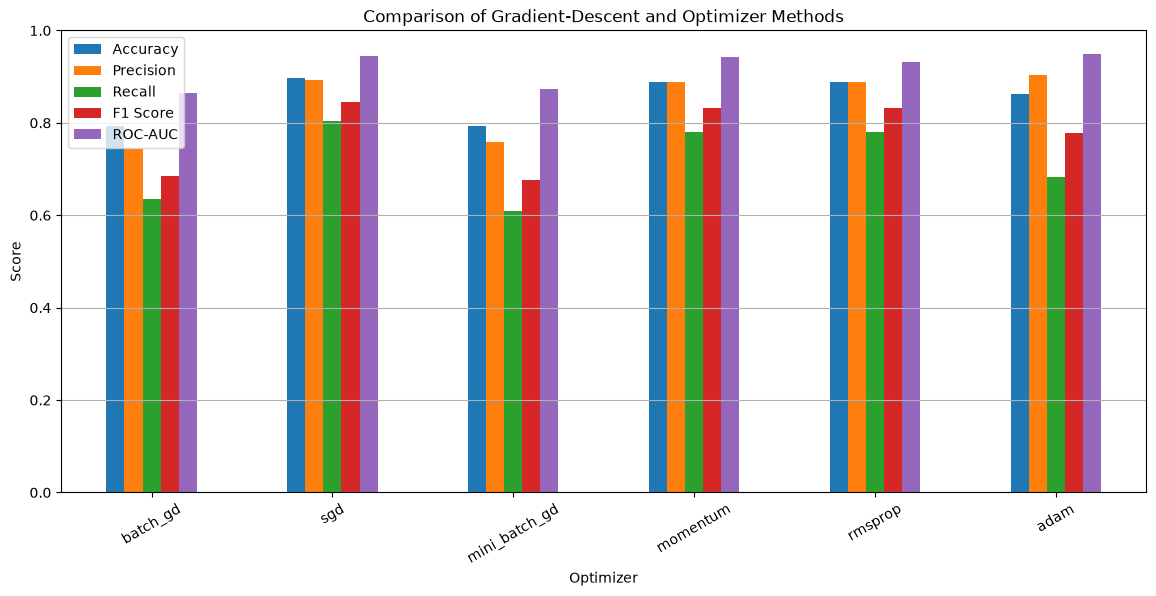

In [105]:
optimizer_results_df.set_index("Optimizer")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Comparison of Gradient-Descent and Optimizer Methods")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.show()

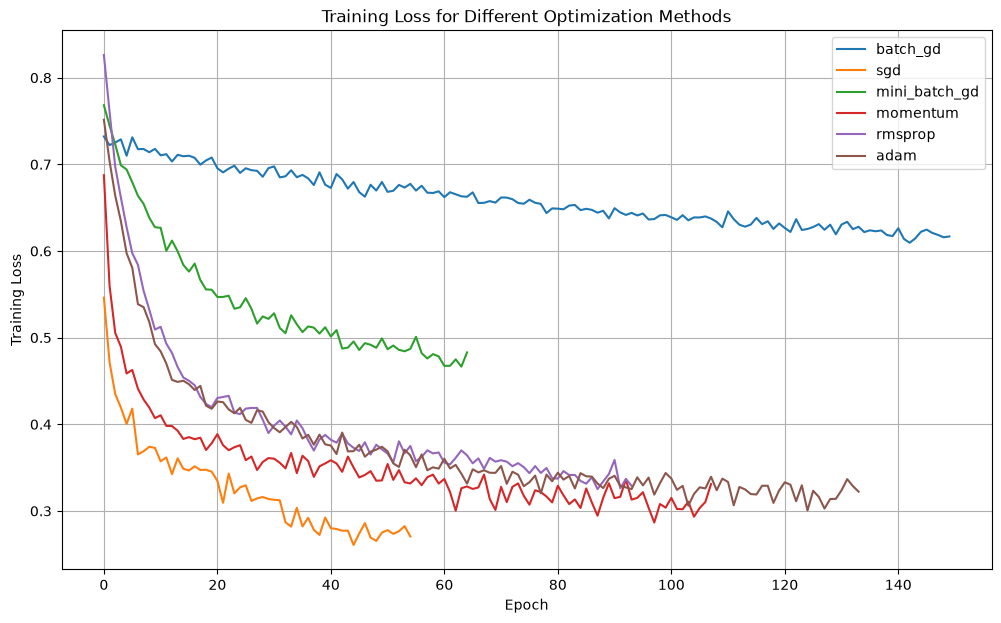

In [106]:
plt.figure(figsize=(12, 7))

for optimizer_name, optimizer_history in optimizer_histories.items():
    plt.plot(
        optimizer_history.history["loss"],
        label=optimizer_name
    )

plt.title("Training Loss for Different Optimization Methods")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid()
plt.show()

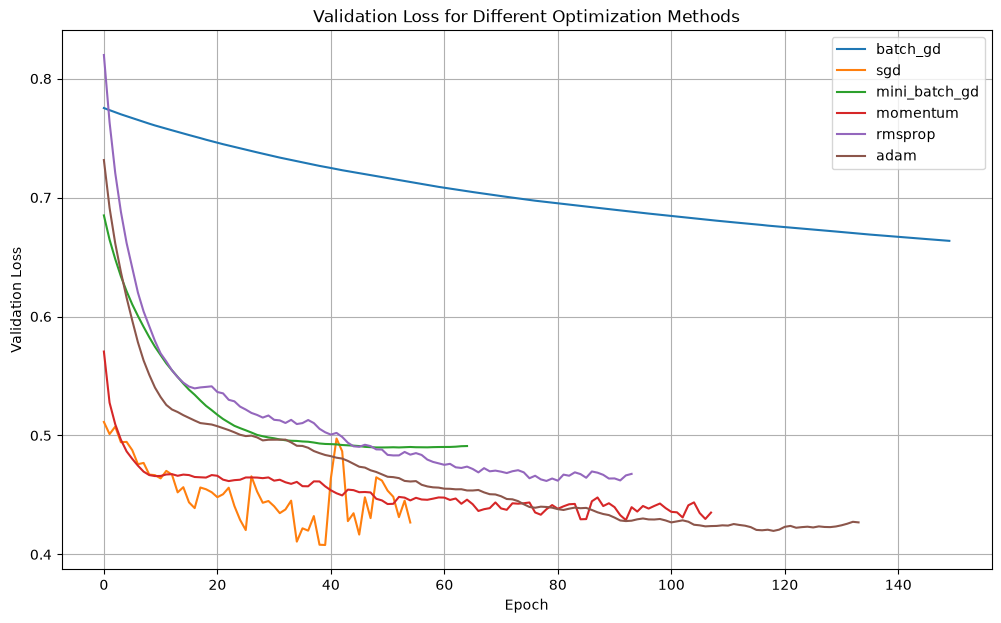

In [107]:
plt.figure(figsize=(12, 7))

for optimizer_name, optimizer_history in optimizer_histories.items():
    plt.plot(
        optimizer_history.history["val_loss"],
        label=optimizer_name
    )

plt.title("Validation Loss for Different Optimization Methods")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid()
plt.show()

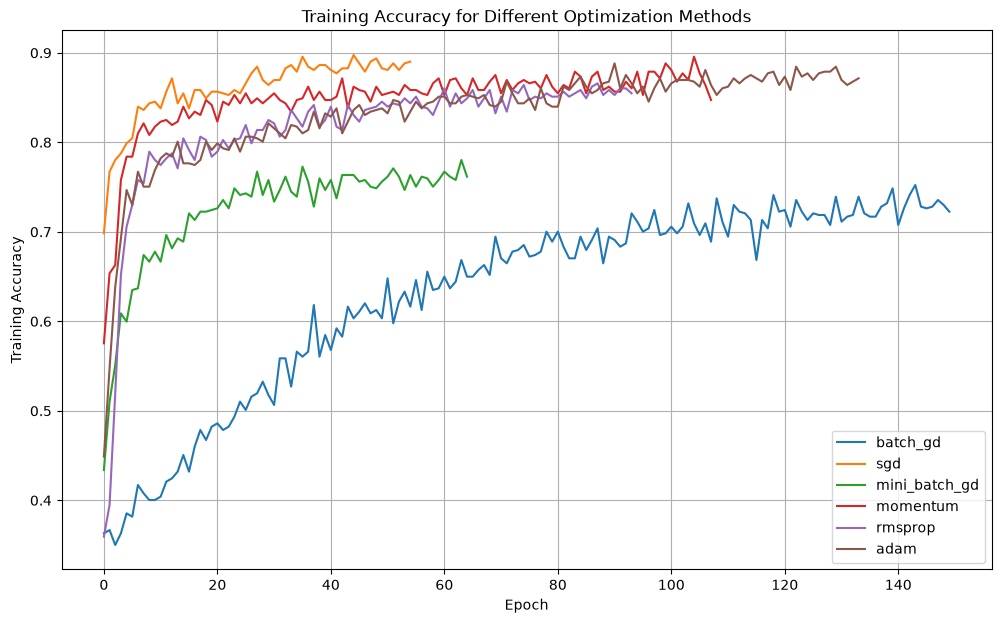

In [108]:
plt.figure(figsize=(12, 7))

for optimizer_name, optimizer_history in optimizer_histories.items():
    plt.plot(
        optimizer_history.history["accuracy"],
        label=optimizer_name
    )

plt.title("Training Accuracy for Different Optimization Methods")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.legend()
plt.grid()
plt.show()

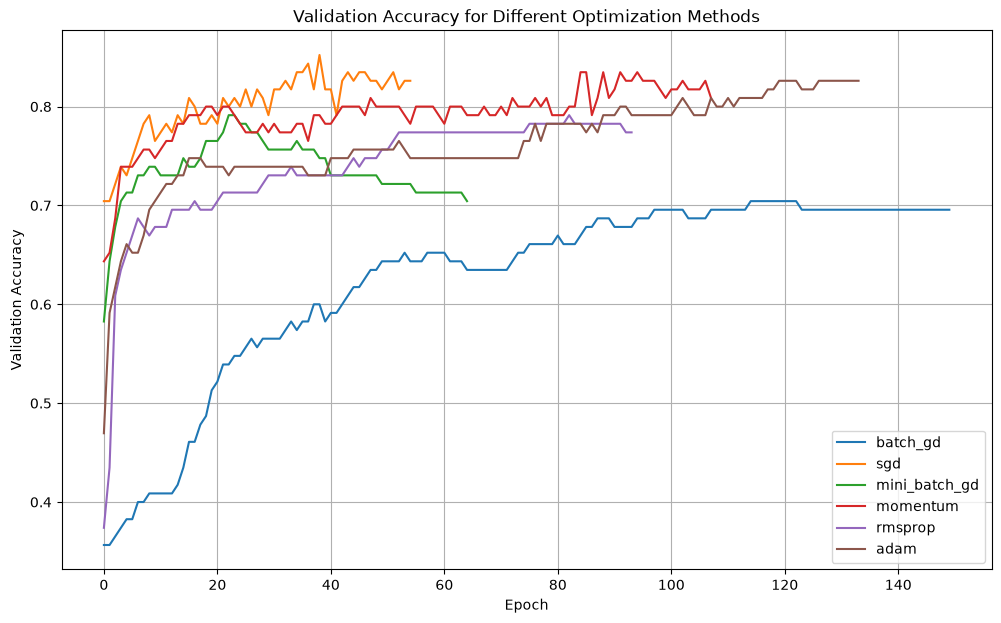

In [109]:
plt.figure(figsize=(12, 7))

for optimizer_name, optimizer_history in optimizer_histories.items():
    plt.plot(
        optimizer_history.history["val_accuracy"],
        label=optimizer_name
    )

plt.title("Validation Accuracy for Different Optimization Methods")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [110]:
optimizer_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Optimizer,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time,Epochs
1,sgd,0.896552,0.891892,0.804878,0.846154,0.945691,53.700721,55
3,momentum,0.887931,0.888889,0.780488,0.831169,0.943415,15.018345,108
4,rmsprop,0.887931,0.888889,0.780488,0.831169,0.931382,13.259169,94
5,adam,0.862069,0.903226,0.682927,0.777778,0.949268,23.244001,134
0,batch_gd,0.793103,0.742857,0.634146,0.684211,0.864065,17.747474,150
2,mini_batch_gd,0.793103,0.757576,0.609756,0.675676,0.872846,8.579972,65


In [111]:
optimizer_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Optimizer,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time,Epochs
1,sgd,0.896552,0.891892,0.804878,0.846154,0.945691,53.700721,55
3,momentum,0.887931,0.888889,0.780488,0.831169,0.943415,15.018345,108
4,rmsprop,0.887931,0.888889,0.780488,0.831169,0.931382,13.259169,94
5,adam,0.862069,0.903226,0.682927,0.777778,0.949268,23.244001,134
0,batch_gd,0.793103,0.742857,0.634146,0.684211,0.864065,17.747474,150
2,mini_batch_gd,0.793103,0.757576,0.609756,0.675676,0.872846,8.579972,65


In [112]:
best_optimizer_row = optimizer_results_df.loc[
    optimizer_results_df["F1 Score"].idxmax()
]

print("Best optimizer based on F1-score:")
print(best_optimizer_row)

Best optimizer based on F1-score:
Optimizer              sgd
Accuracy          0.896552
Precision         0.891892
Recall            0.804878
F1 Score          0.846154
ROC-AUC           0.945691
Training Time    53.700721
Epochs                  55
Name: 1, dtype: object


In [113]:
best_auc_row = optimizer_results_df.loc[
    optimizer_results_df["ROC-AUC"].idxmax()
]

print("Best optimizer based on ROC-AUC:")
print(best_auc_row)

Best optimizer based on ROC-AUC:
Optimizer             adam
Accuracy          0.862069
Precision         0.903226
Recall            0.682927
F1 Score          0.777778
ROC-AUC           0.949268
Training Time    23.244001
Epochs                 134
Name: 5, dtype: object
